# Employee Attrition Analysis

## Project objective
Analyze employee attrition patterns and build a baseline model to estimate whether an employee record is associated with attrition. This is an educational analysis of a public, fictional/synthetic HR dataset—not a tool for making employment decisions.

## Dataset
Download the IBM HR Analytics Employee Attrition & Performance dataset from Kaggle and place `WA_Fn-UseC_-HR-Employee-Attrition.csv` in this project folder. Dataset source: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, recall_score, roc_auc_score,
                             RocCurveDisplay)

sns.set_theme()
DATA_PATH = Path('WA_Fn-UseC_-HR-Employee-Attrition.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Cannot find {DATA_PATH}. Download the CSV from the dataset link in the README '
        'and place it beside this notebook.'
    )
df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
display(df.head())


Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Inspect and prepare the data
We check column types, missing values, duplicate rows, and the target distribution before analysis.

In [4]:
display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(10))
print('Duplicate rows:', df.duplicated().sum())
print('\nAttrition counts:')
display(df['Attrition'].value_counts())
print('\nAttrition percentages:')
display((df['Attrition'].value_counts(normalize=True) * 100).round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

None

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


Duplicate rows: 0

Attrition counts:


,count
Attrition,
No,1233
Yes,237



Attrition percentages:


,proportion
Attrition,
No,83.88
Yes,16.12


## 2. Exploratory data analysis (EDA)
These charts describe patterns in this dataset. Associations do not prove that a factor causes an employee to leave.

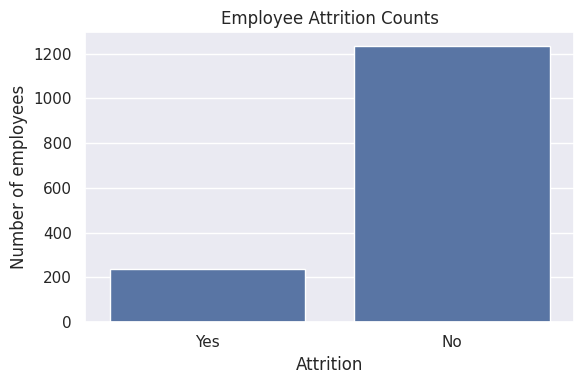

,Attrition rate (%)
OverTime,
Yes,30.53
No,10.44


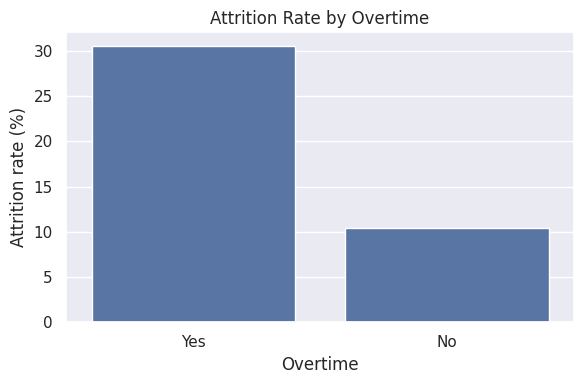

,Attrition rate (%)
Department,
Sales,20.63
Human Resources,19.05
Research & Development,13.84


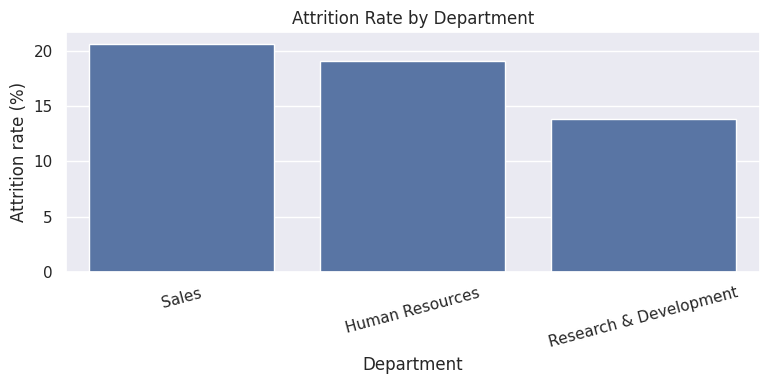

,Attrition rate (%)
JobSatisfaction,
1,22.84
2,16.43
3,16.52
4,11.33


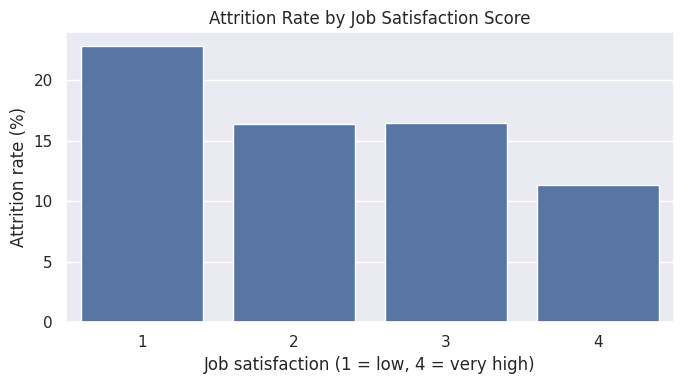

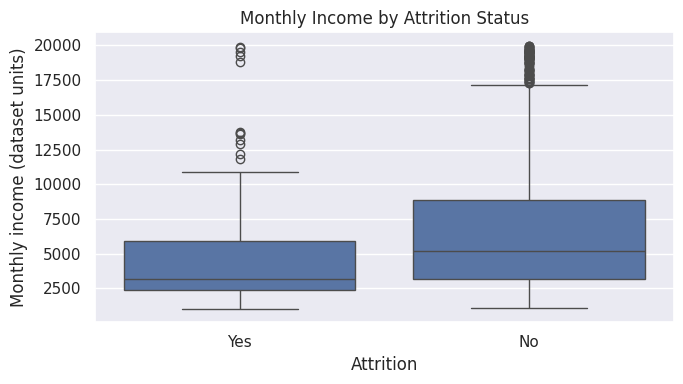

In [5]:
# Overall attrition distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Attrition')
plt.title('Employee Attrition Counts')
plt.xlabel('Attrition')
plt.ylabel('Number of employees')
plt.tight_layout()
plt.show()

# Attrition rate by overtime
overtime_rate = (df.groupby('OverTime')['Attrition']
                  .apply(lambda s: (s == 'Yes').mean() * 100)
                  .sort_values(ascending=False))
display(overtime_rate.rename('Attrition rate (%)').round(2))
plt.figure(figsize=(6, 4))
sns.barplot(x=overtime_rate.index, y=overtime_rate.values)
plt.title('Attrition Rate by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition rate (%)')
plt.tight_layout()
plt.show()

# Attrition rate by department
department_rate = (df.groupby('Department')['Attrition']
                     .apply(lambda s: (s == 'Yes').mean() * 100)
                     .sort_values(ascending=False))
display(department_rate.rename('Attrition rate (%)').round(2))
plt.figure(figsize=(8, 4))
sns.barplot(x=department_rate.index, y=department_rate.values)
plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition rate (%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Job satisfaction comparison
satisfaction_rate = (df.groupby('JobSatisfaction')['Attrition']
                       .apply(lambda s: (s == 'Yes').mean() * 100))
display(satisfaction_rate.rename('Attrition rate (%)').round(2))
plt.figure(figsize=(7, 4))
sns.barplot(x=satisfaction_rate.index, y=satisfaction_rate.values)
plt.title('Attrition Rate by Job Satisfaction Score')
plt.xlabel('Job satisfaction (1 = low, 4 = very high)')
plt.ylabel('Attrition rate (%)')
plt.tight_layout()
plt.show()

# Monthly income by attrition status
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome')
plt.title('Monthly Income by Attrition Status')
plt.xlabel('Attrition')
plt.ylabel('Monthly income (dataset units)')
plt.tight_layout()
plt.show()


## 3. Build a baseline classification model
We use a train/test split and a preprocessing pipeline to avoid fitting encoders on the test set. Because attrition classes are imbalanced, we report recall and ROC-AUC in addition to accuracy. Do not use this educational model to make hiring, firing, promotion, or employee-monitoring decisions.

Accuracy: 0.752
Attrition-class recall: 0.638
ROC-AUC: 0.803

Classification report:
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



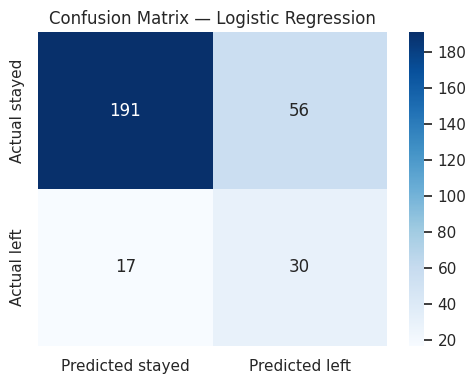

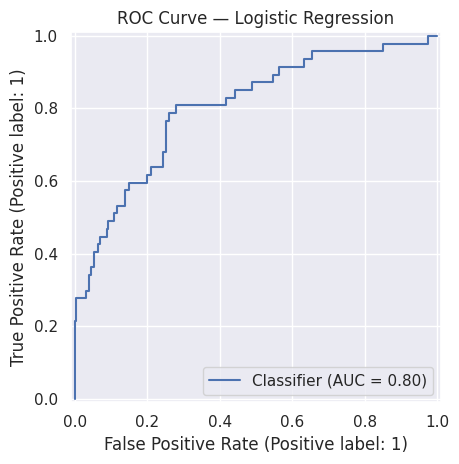

In [6]:
# Remove columns that are constant or identifiers in this dataset.
drop_candidates = ['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
X = df.drop(columns=['Attrition'] + [c for c in drop_candidates if c in df.columns])
y = (df['Attrition'] == 'Yes').astype(int)

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced'))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'Attrition-class recall: {recall_score(y_test, y_pred):.3f}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Left'], zero_division=0))

ConfusionMatrixDisplay = None
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted stayed', 'Predicted left'],
            yticklabels=['Actual stayed', 'Actual left'])
plt.title('Confusion Matrix — Logistic Regression')
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title('ROC Curve — Logistic Regression')
plt.tight_layout()
plt.show()


## 4. Findings and recommendations
After running all cells, write down the actual patterns shown by your charts and metrics. Do not copy assumed results without checking your own outputs.

Suggested questions:
- Which department has the highest attrition rate in this dataset?
- How does attrition differ between employees with and without overtime?
- Does job satisfaction appear associated with attrition?
- Why is recall useful when the class of interest is employees who left?
- What limitations arise from using an old, fictional HR dataset?

## Ethics and limitations
- The dataset is a public educational sample, not live company data.
- Correlation is not causation.
- The model can make mistakes and may reflect biases in the data.
- Do not use predictions to penalize, monitor, or make employment decisions about real people.


## Results and Findings

### 1. Project Overview
This project analyzes employee attrition using the IBM HR Analytics dataset containing 1,470 employee records and 35 columns.

### 2. Data Analysis
The dataset was inspected for missing values, duplicate records, and attrition distribution. Exploratory data analysis was performed to examine attrition patterns across overtime, department, job satisfaction, and monthly income.

### 3. Machine Learning Model
A Logistic Regression classification model was trained using an 80/20 train-test split. Categorical features were encoded, numerical features were scaled, and class weighting was used to help address class imbalance.

### 4. Model Performance
- Accuracy: 75.2%
- Attrition-class recall: 63.8%
- ROC-AUC: 0.803

The model achieved a reasonable baseline result. Recall indicates that it identified approximately 63.8% of employees who left in the test set. Further improvements may be possible through model comparison and feature engineering.

### 5. Recommendations
Organizations can use aggregate, voluntary employee feedback and workplace analysis to investigate potential retention improvements. The analysis does not establish causation, and predictions should not be used to make decisions about individual employees.

### 6. Limitations
The dataset is an educational sample and may not represent real organizations. Model performance on this dataset does not guarantee performance on other data. The project is intended for learning and demonstration purposes only.